# Argentina Inflation (CPI) 2016-Present: Cleaning and Analysis

**Data:** National CPI, general level, base December 2016 = 100.
Source: INDEC via datos.gob.ar. Downloaded on 2026-10-30. Coverage: December 2016 to September 2026.

## 1. Setup
I import `pandas` for working with tables and `matplotlib` for charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the data
I load the CSV directly from the datos.gob.ar catalog. The server rejected
the default request (HTTP 403), so I send a browser-style `User-Agent` header.
The file includes regional CPI columns and INDEC's own variations.

In [2]:
url = "https://infra.datos.gob.ar/catalog/sspm/dataset/145/distribution/145.3/download/indice-precios-al-consumidor-nivel-general-base-diciembre-2016-mensual.csv"

df = pd.read_csv(url, storage_options={"User-Agent": "Mozilla/5.0"})

## 3. Inspect the data
Before changing anything, I check the structure with `head()`, `tail()`, and `info()`.

**What I see:**
- 118 rows covering 2016-12-01 to 2026-09-01
- Columns: national CPI, regional CPIs, variations (monthly and with respect to December last year)
- The date column is stored as text, not as dates
- Missing values: one null value for each first period variation (no previous period to compare it to)

In [3]:
df.head()

,indice_tiempo,ipc_ng_nacional,ipc_ng_gba,ipc_ng_pampeana,ipc_ng_nea,ipc_ng_noa,ipc_ng_cuyo,ipc_ng_patagonia,ipc_ng_nacional_tasa_variacion_mensual,ipc_ng_gba_tasa_variacion_mensual,...,ipc_ng_noa_tasa_variacion_mensual,ipc_ng_cuyo_tasa_variacion_mensual,ipc_ng_patagonia_tasa_variacion_mensual,ipc_ng_nacional_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_gba_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_pampeana_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_nea_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_noa_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_cuyo_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_patagonia_tasa_variacion_acumulada_dic_ano_anterior
0,2016-12-01,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017-01-01,101.5859,101.3130,101.7874,101.6727,101.6014,101.7074,102.5593,0.015859,0.013130,...,0.016014,0.017074,0.025593,0.015859,0.013130,0.017874,0.016727,0.016014,0.017074,0.025593
2,2017-02-01,103.6859,103.8085,103.5312,103.4617,103.7115,103.2652,104.2827,0.020672,0.024632,...,0.020768,0.015316,0.016804,0.036859,0.038085,0.035312,0.034617,0.037115,0.032652,0.042827
3,2017-03-01,106.1476,106.2627,105.8173,105.9880,107.0550,105.9238,106.5167,0.023742,0.023642,...,0.032238,0.025745,0.021423,0.061476,0.062627,0.058173,0.059880,0.070550,0.059238,0.065167
4,2017-04-01,108.9667,109.0613,108.6912,108.3473,109.9626,109.4506,108.6517,0.026558,0.026337,...,0.027160,0.033296,0.020044,0.089667,0.090613,0.086912,0.083473,0.099626,0.094506,0.086517


In [4]:
df.tail()

,indice_tiempo,ipc_ng_nacional,ipc_ng_gba,ipc_ng_pampeana,ipc_ng_nea,ipc_ng_noa,ipc_ng_cuyo,ipc_ng_patagonia,ipc_ng_nacional_tasa_variacion_mensual,ipc_ng_gba_tasa_variacion_mensual,...,ipc_ng_noa_tasa_variacion_mensual,ipc_ng_cuyo_tasa_variacion_mensual,ipc_ng_patagonia_tasa_variacion_mensual,ipc_ng_nacional_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_gba_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_pampeana_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_nea_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_noa_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_cuyo_tasa_variacion_acumulada_dic_ano_anterior,ipc_ng_patagonia_tasa_variacion_acumulada_dic_ano_anterior
113,2026-05-01,11607.3937,11594.5499,11556.8543,11725.5958,11747.5318,11750.0933,11622.7473,0.021500,0.022758,...,0.020936,0.020761,0.016899,0.146820,0.146197,0.143382,0.176279,0.158869,0.145744,0.132973
114,2026-06-01,11826.4103,11810.9464,11792.0130,11951.8421,11943.1627,11937.3726,11811.1393,0.018869,0.018664,...,0.016653,0.015939,0.016209,0.168459,0.167589,0.166647,0.198975,0.178167,0.164005,0.151337
115,2026-07-01,12076.3937,12078.7372,12027.5347,12190.8218,12181.1952,12160.2347,12051.1073,0.021138,0.022673,...,0.019930,0.018669,0.020317,0.193158,0.194062,0.189949,0.222949,0.201649,0.185736,0.174729
116,2026-08-01,12276.7660,12276.8120,12223.9951,12404.6845,12397.9365,12360.9149,12265.2749,0.016592,0.016399,...,0.017793,0.016503,0.017772,0.212955,0.213643,0.209386,0.244403,0.223030,0.205304,0.195606
117,2026-09-01,12514.1508,12523.1733,12463.7838,12615.4271,12631.4816,12591.9359,12434.4545,0.019336,0.020067,...,0.018837,0.018690,0.013793,0.236409,0.237997,0.233109,0.265544,0.246069,0.227831,0.212097


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 22 columns):
 #   Column                                                      Non-Null Count  Dtype  
---  ------                                                      --------------  -----  
 0   indice_tiempo                                               118 non-null    str    
 1   ipc_ng_nacional                                             118 non-null    float64
 2   ipc_ng_gba                                                  118 non-null    float64
 3   ipc_ng_pampeana                                             118 non-null    float64
 4   ipc_ng_nea                                                  118 non-null    float64
 5   ipc_ng_noa                                                  118 non-null    float64
 6   ipc_ng_cuyo                                                 118 non-null    float64
 7   ipc_ng_patagonia                                            118 non-null    float64
 8   ipc_ng_naci

## 4. Clean the data
Steps:
1. Keep only the national general-level CPI.
2. Rename columns to `date` and `cpi`.
3. Convert `date` to a real datetime so pandas can do time-based calculations.
4. Set `date` as the index, which is standard for time series.

In [6]:
df = df[["indice_tiempo", "ipc_ng_nacional"]].copy()
df.columns = ["date", "cpi"]
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

## 5. Compute inflation rates
The CPI is an index *level*, not an inflation rate, so I calculate the rates myself:

- **MoM** = percentage change vs. the previous month (`pct_change()`)
- **YoY** = percentage change vs. the same month a year earlier (`pct_change(12)`)

The first rows are empty (`NaN`) because there is no earlier
period to compare with.

In [7]:
df["mom"] = df["cpi"].pct_change() * 100
df["yoy"] = df["cpi"].pct_change(12) * 100

## 6. CPI level
The index rose from 100 in December 2016 to about 12514 in September 2026.
I use a **log scale** because inflation compounds: on a log scale, a steady
slope means a steady inflation rate.

**Observation:** the slope steepens notably around the end of 2023.

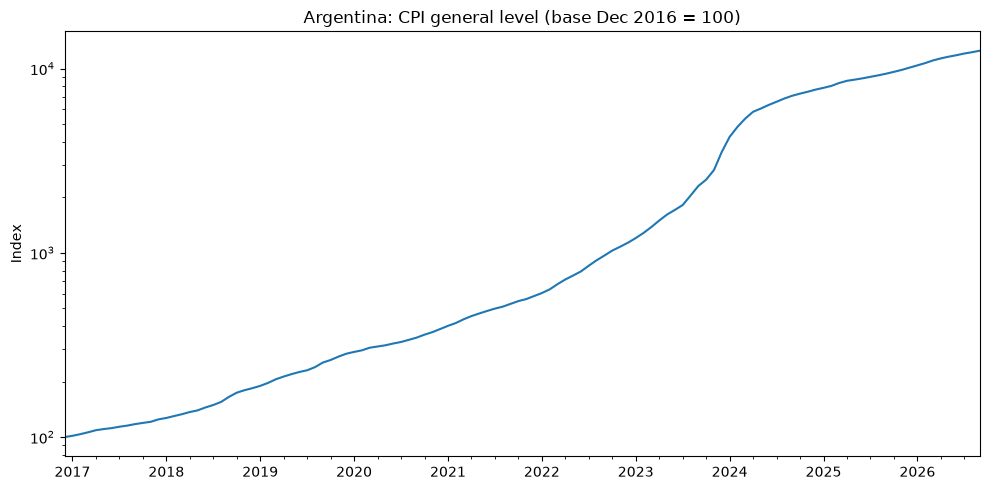

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
df["cpi"].plot(ax=ax)
ax.set_title("Argentina: CPI general level (base Dec 2016 = 100)")
ax.set_ylabel("Index")
ax.set_xlabel("")
ax.set_yscale("log")
fig.tight_layout()
fig.savefig("charts/cpi_level.png", dpi=150)
plt.show()

## 7. Monthly inflation (MoM)
Bars show monthly inflation since 2023.

**Observation:** monthly inflation peaked at 25.47% in December 2023, then fell to
4.18% by May 2024.

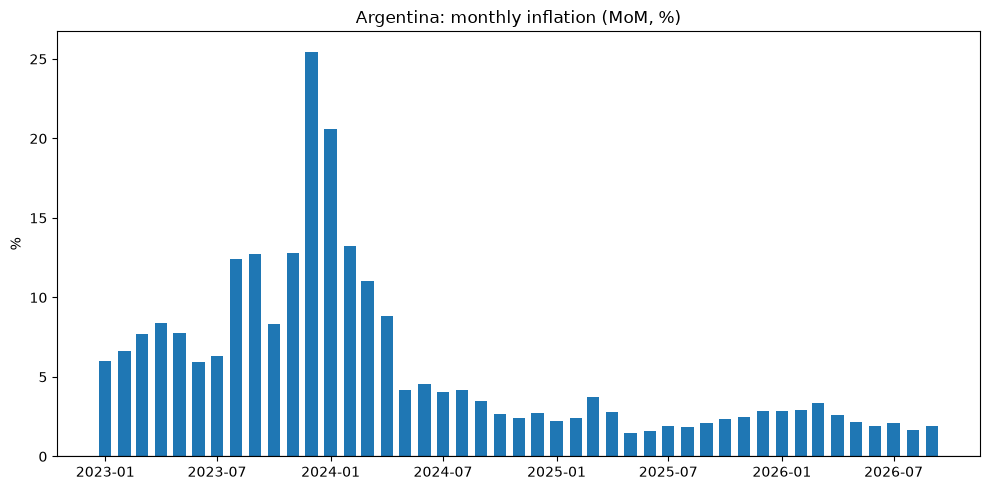

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
recent = df.loc["2023":]
ax.bar(recent.index, recent["mom"], width=20)
ax.set_title("Argentina: monthly inflation (MoM, %)")
ax.set_ylabel("%")
ax.axhline(0, color="black", linewidth=0.8)
fig.tight_layout()
fig.savefig("charts/mom.png", dpi=150)
plt.show()

## 8. Annual inflation (YoY)
**Observation:** YoY inflation peaked near 289.4% in April 2024 and has since
stabilized around 33%.

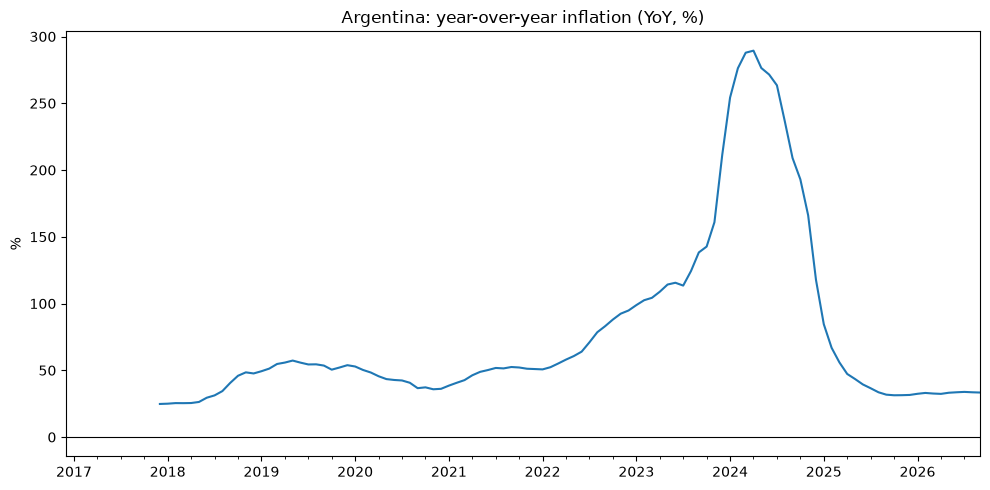

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
df["yoy"].plot(ax=ax)
ax.set_title("Argentina: year-over-year inflation (YoY, %)")
ax.set_ylabel("%")
ax.set_xlabel("")
ax.axhline(0, color="black", linewidth=0.8)
fig.tight_layout()
fig.savefig("charts/yoy.png", dpi=150)
plt.show()

## 9. Conclusions
- Monthly inflation peaked at 25.47% in December 2023, then fell rapidly.
- YoY inflation peaked near 289.4% in April 2024.

## Limitations
- This analysis describes inflation; it does not forecast it or explain its causes.
- Regional differences are not analyzed here.

In [11]:
df.to_csv("data/cpi_clean.csv")